# Unit 5 exercise — worked solution

In [1]:
import math9102 as m9
import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats

m9.use_house_style()

survey = m9.load_survey()
youth = m9.load_youthcohort()

---

## Question 1 — Self-esteem across age groups

### 1.1 Hypotheses

> **H₀:** Mean self-esteem is the same in all three age groups.
>
> **H₁:** Mean self-esteem differs in at least one age group.

"The three age groups have different self-esteem" is the weak version of H₁: a
significant omnibus test does not support it, because one group differing from
the other two is enough to reject H₀.

### 1.2 Inspect

In [2]:
ages = ["18 - 29", "30 - 44", "45+"]
m9.frequency(survey, "agegp3")

,count,percent,valid_percent
agegp3,,,
18 - 29,149,33.94,33.94
30 - 44,153,34.85,34.85
45+,137,31.21,31.21


In [3]:
m9.describe_by(survey, "tslfest", "agegp3")

,n,missing,mean,sd,se,median,iqr,min,max,skew,kurtosis
agegp3,,,,,,,,,,,
18 - 29,149.0,0.0,32.597,5.589,0.458,34.0,8.0,18.0,40.0,-0.643,-0.509
30 - 44,152.0,1.0,33.586,5.288,0.429,35.0,8.0,18.0,40.0,-1.034,0.728
45+,135.0,2.0,34.504,5.151,0.443,36.0,8.0,20.0,40.0,-1.020,0.329


In [4]:
missing = m9.missingness(survey, ["tslfest", "agegp3"])
print(missing.attrs["summary"])

Listwise deletion across these 2 column(s) keeps 436 of 439 rows (loses 3, 0.7%).


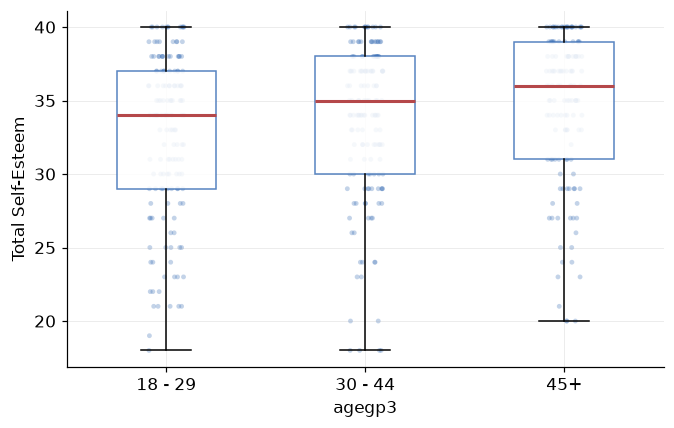

In [5]:
m9.grouped_box(survey, "tslfest", "agegp3", ylabel="Total Self-Esteem", order=ages);

### 1.3 Assumptions

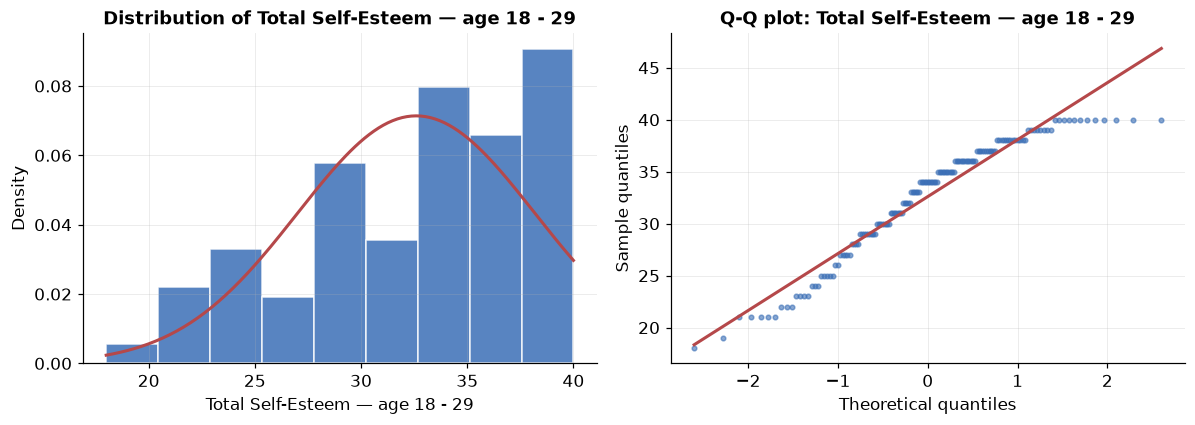

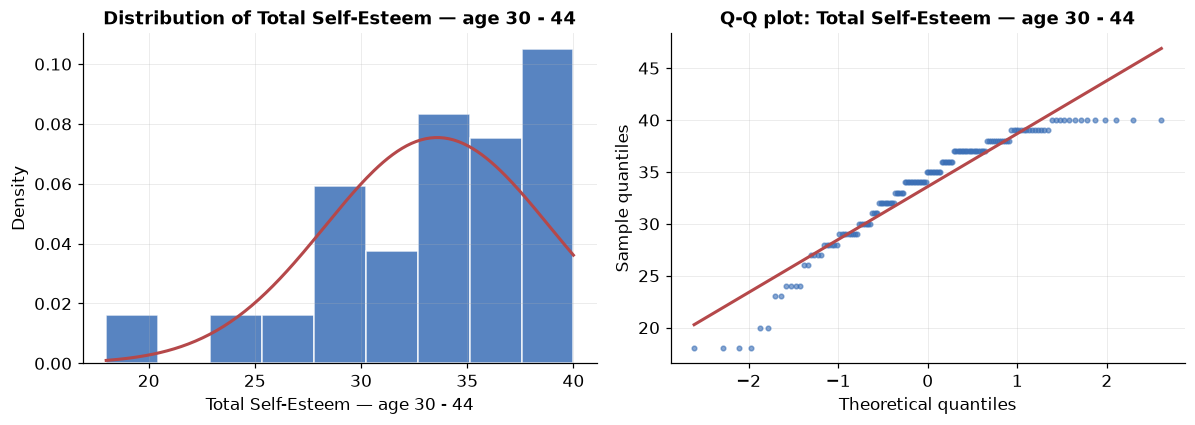

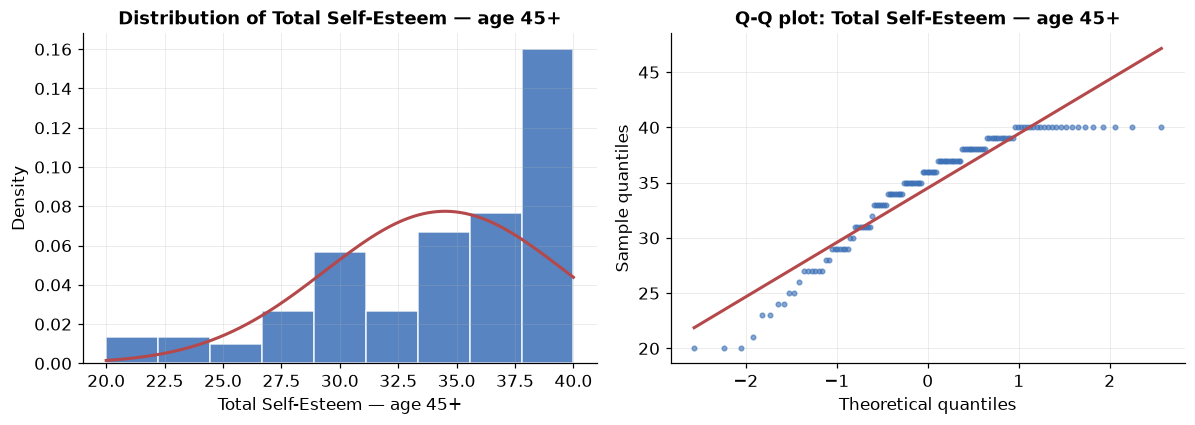

In [6]:
for age in ages:
    m9.normality_panel(survey.loc[survey.agegp3 == age, "tslfest"],
                       label=f"Total Self-Esteem — age {age}")

In [7]:
se = survey[["tslfest", "agegp3"]].dropna()
groups = [se.loc[se.agegp3 == a, "tslfest"] for a in ages]

sds = [g.std(ddof=1) for g in groups]
print(f"largest SD / smallest SD = {max(sds) / min(sds):.2f}")
print(f"highest possible score reached in every group: {all(g.max() == 40 for g in groups)}")

largest SD / smallest SD = 1.09
highest possible score reached in every group: True


Every group is skewed to the left, and the Q-Q plots flatten at the top: the
scale has a ceiling, and a cluster of respondents sit on it. The bend is
confined to the upper tail, each group has well over a hundred people, and the
spreads are close. Welch's ANOVA is defensible. Because the skew is visible, a
Kruskal–Wallis test is a sensible check that the conclusion does not hang on
the choice:

In [8]:
print(f"Kruskal-Wallis, as a check: {m9.fmt_p(stats.kruskal(*groups).pvalue)}")

Kruskal-Wallis, as a check: *p* = .007


**What a weak answer looks like.** "Levene's test was not significant, so the
variances are equal and ANOVA is appropriate." That makes the choice depend on
a variance test, which is the one thing the question ruled out, and says
nothing about the shape of the groups.

### 1.4 Omnibus and follow-up

In [9]:
welch = stats.f_oneway(*groups, equal_var=False)
pg.welch_anova(data=se, dv="tslfest", between="agegp3")

,Source,ddof1,ddof2,F,p_unc,np2
0,agegp3,2,287.542412,4.462825,0.012339,0.020384


The omnibus test is significant, so the follow-up is warranted:

In [10]:
gh = pg.pairwise_gameshowell(data=se, dv="tslfest", between="agegp3")
gh[["A", "B", "diff", "pval", "hedges"]]

,A,B,diff,pval,hedges
0,18 - 29,30 - 44,-0.988211,0.258063,-0.181218
1,18 - 29,45+,-1.906388,0.008479,-0.353031
2,30 - 44,45+,-0.918177,0.298005,-0.175288


### 1.5 Effect size

In [11]:
omega2 = m9.omega_squared(groups)
print(f"eta squared = {m9.eta_squared(groups):.3f}")
print(f"omega squared = {omega2:.3f} ({m9.interpret(omega2, 'eta2')})")

eta squared = 0.020
omega squared = 0.016 (small)


### 1.6 Report and conclude

In [12]:
m9.report_anova(survey, "tslfest", "agegp3", welch,
                outcome_label="Total Self-Esteem", order=ages)

Welch's one-way ANOVA was conducted to compare Total Self-Esteem across 3 groups: 18 - 29 (*n* = 149, *M* = 32.60, *SD* = 5.59); 30 - 44 (*n* = 152, *M* = 33.59, *SD* = 5.29); 45+ (*n* = 135, *M* = 34.50, *SD* = 5.15). There was a statistically significant difference between the groups, *F*(2, 287.5) = 4.46, *p* = .012, η² = .020, ω² = .016 (small). The test establishes that the group means are not all equal; it does not say which of them differ, which is what the post-hoc comparisons are for.

In [13]:
sig = gh[gh.pval < 0.05]
pairs_txt = "; ".join(
    f"{row.B} against {row.A} (difference {row.diff:+.2f}, {m9.fmt_p(row.pval)})"
    for row in sig.itertuples()
)
m9.md(f"Games-Howell comparisons found {len(sig)} of {len(gh)} pairs to differ: {pairs_txt}.")

Games-Howell comparisons found 1 of 3 pairs to differ: 45+ against 18 - 29 (difference -1.91, *p* = .008).

**Conclusion.** There is evidence to reject H₀. The difference the post-hoc
comparisons can locate is between the youngest and the oldest groups, with the
middle group indistinguishable from either, and the effect is small. As with
optimism in the notebook, these are different people in each age band, measured
once, so the result does not show that self-esteem rises as people age.

---

## Question 2 — Perceived stress across education levels

### 2.1 Inspect before anything else

In [14]:
m9.frequency(survey, "educ")

,count,percent,valid_percent
educ,,,
COMPLETED HIGHSCHOOL,85,19.36,19.36
COMPLETED UNDERGRADUATE,123,28.02,28.02
POSTGRADUATE COMPLETED,56,12.76,12.76
PRIMARY,2,0.46,0.46
SOME ADDITIONAL TRAINING,120,27.33,27.33
SOME SECONDARY,53,12.07,12.07


**Two decisions.**

1. **The order.** Education is ordinal, but it is stored as text and prints
   alphabetically, with `PRIMARY` in the middle. Every table and plot needs the
   order written out.
2. **A group of two.** `PRIMARY` has two respondents. A group of two cannot
   describe anybody: its standard deviation rests on one degree of freedom, and
   whatever its mean is, it is two people's mean.

**What to do with it.** Two defensible answers:

- **Merge** it into `SOME SECONDARY`, giving a category of "did not complete
  secondary school". The merged category means something, and nobody is lost.
- **Drop** it, and say in the report that two respondents with primary
  education only were excluded because the group is too small to analyse.

This solution merges. Both choices are shown below to lead to the same
conclusion, which is worth checking whenever a decision like this is made.

**What a weak answer looks like.** Running the test on all six categories
without comment. Silently deleting the two rows is almost as bad: the decision
may be right, but a reader cannot check a decision they are not told about.

In [15]:
educ_order = ["SOME SECONDARY", "COMPLETED HIGHSCHOOL", "SOME ADDITIONAL TRAINING",
              "COMPLETED UNDERGRADUATE", "POSTGRADUATE COMPLETED"]
stress = survey[["tpstress", "educ"]].dropna().copy()
stress["educ"] = stress.educ.replace({"PRIMARY": "SOME SECONDARY"})

### 2.2 Hypotheses

> **H₀:** Mean perceived stress is the same at every level of education.
>
> **H₁:** Mean perceived stress differs at one or more levels of education.

### 2.3 Assumptions

In [16]:
m9.describe_by(stress, "tpstress", "educ").reindex(educ_order)

,n,missing,mean,sd,se,median,iqr,min,max,skew,kurtosis
educ,,,,,,,,,,,
SOME SECONDARY,53.0,0.0,27.472,6.670,0.916,26.0,11.00,17.0,43.0,0.564,-0.429
COMPLETED HIGHSCHOOL,84.0,0.0,27.369,6.075,0.663,26.0,9.00,12.0,44.0,0.117,0.104
SOME ADDITIONAL TRAINING,117.0,0.0,26.991,5.328,0.493,27.0,6.00,13.0,41.0,0.079,0.516
COMPLETED UNDERGRADUATE,123.0,0.0,26.016,5.513,0.497,26.0,7.50,12.0,39.0,-0.125,-0.255
POSTGRADUATE COMPLETED,56.0,0.0,26.071,6.376,0.852,25.5,8.25,14.0,46.0,0.758,0.972


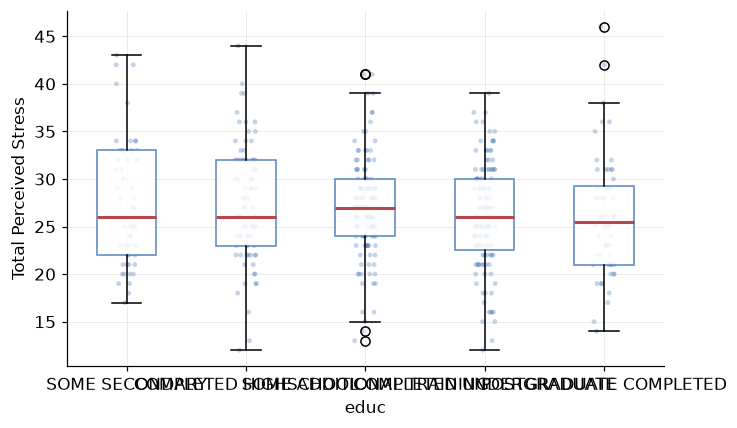

In [17]:
m9.grouped_box(stress, "tpstress", "educ", ylabel="Total Perceived Stress",
               order=educ_order);

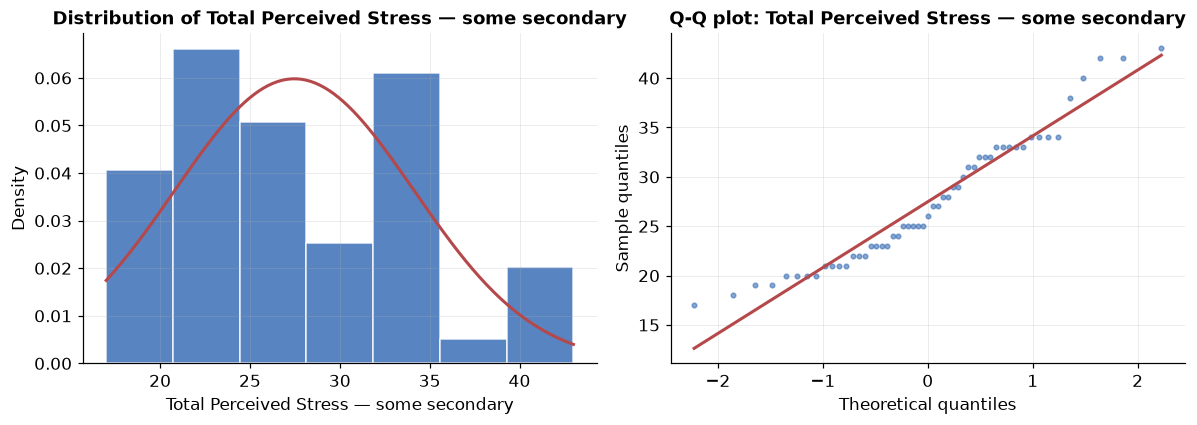

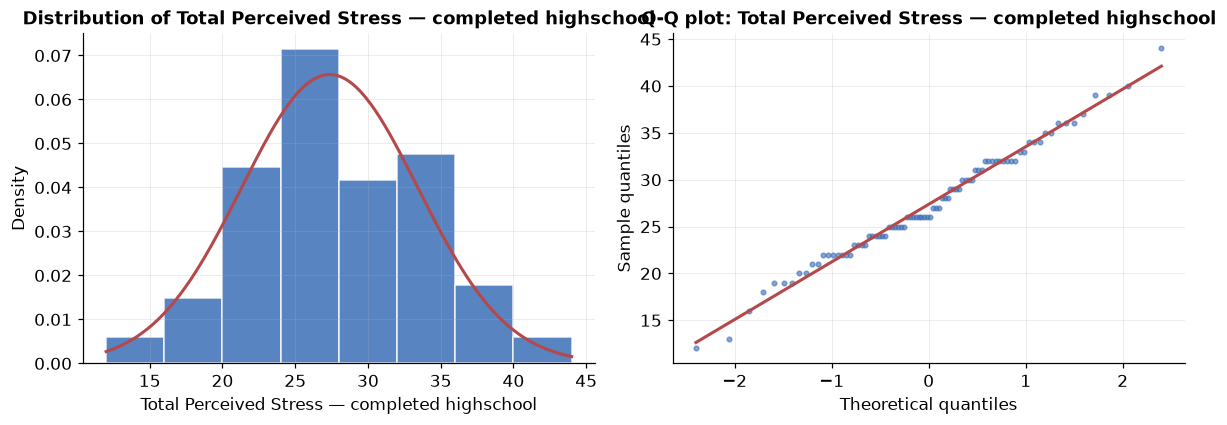

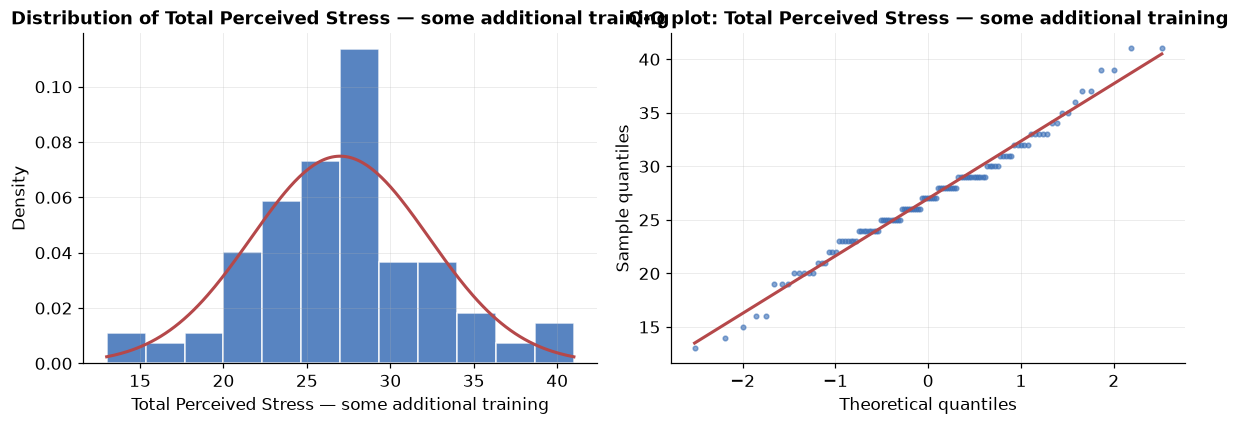

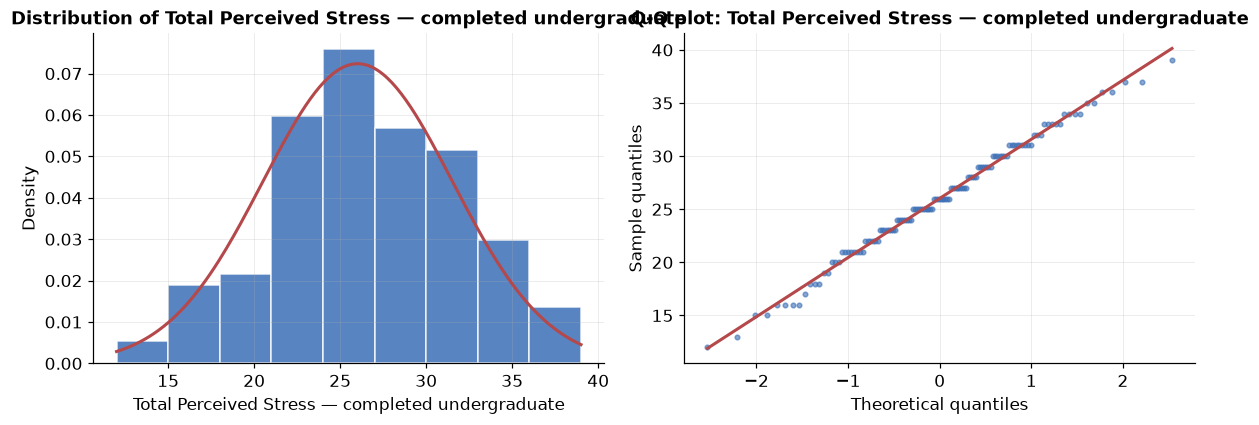

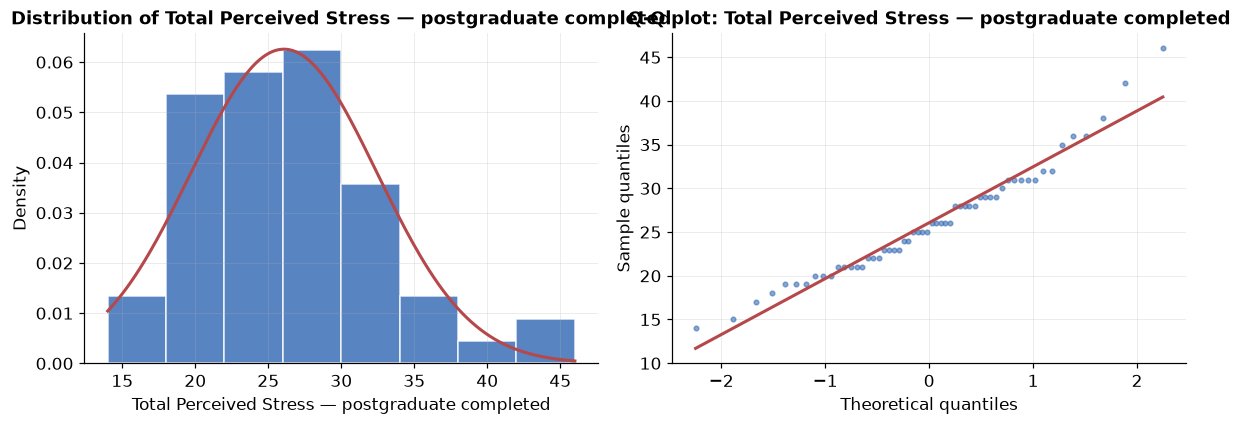

In [18]:
for level in educ_order:
    m9.normality_panel(stress.loc[stress.educ == level, "tpstress"],
                       label=f"Total Perceived Stress — {level.lower()}")

Three groups are close to symmetric. The postgraduate and some-secondary groups
lean to the right — visible in their skew and at the top of their Q-Q plots —
with fifty-odd people in each. The spreads are similar. Welch's ANOVA is
defensible, and a rank test is a cheap check that the lean does not decide the
result:

In [19]:
check = [stress.loc[stress.educ == lv, "tpstress"] for lv in educ_order]
print(f"Kruskal-Wallis, as a check: {m9.fmt_p(stats.kruskal(*check).pvalue)}")

Kruskal-Wallis, as a check: *p* = .387


### 2.4 Run, size and report

In [20]:
stress_groups = [stress.loc[stress.educ == lv, "tpstress"] for lv in educ_order]
stress_welch = stats.f_oneway(*stress_groups, equal_var=False)

m9.report_anova(stress, "tpstress", "educ", stress_welch,
                outcome_label="Total Perceived Stress", order=educ_order)

Welch's one-way ANOVA was conducted to compare Total Perceived Stress across 5 groups: SOME SECONDARY (*n* = 53, *M* = 27.47, *SD* = 6.67); COMPLETED HIGHSCHOOL (*n* = 84, *M* = 27.37, *SD* = 6.08); SOME ADDITIONAL TRAINING (*n* = 117, *M* = 26.99, *SD* = 5.33); COMPLETED UNDERGRADUATE (*n* = 123, *M* = 26.02, *SD* = 5.51); POSTGRADUATE COMPLETED (*n* = 56, *M* = 26.07, *SD* = 6.38). There was no statistically significant difference between the groups, *F*(4, 171.9) = 1.12, *p* = .351, η² = .011, ω² = .001 (negligible). This is not evidence that the group means are equal: the data do not provide sufficient evidence that they differ.

Not significant, so **no post-hoc comparisons**. Dropping the two respondents
instead of merging them changes nothing:

In [21]:
dropped = survey[["tpstress", "educ"]].dropna()
dropped = dropped[dropped.educ != "PRIMARY"]
print(f"merged:  {m9.fmt_p(stress_welch.pvalue)}")
print(f"dropped: {m9.fmt_p(stats.f_oneway(*[g.tpstress for _, g in dropped.groupby('educ')], equal_var=False).pvalue)}")

merged:  *p* = .351
dropped: *p* = .360


And the analysis the question asked you not to run:

In [22]:
everything = survey[["tpstress", "educ"]].dropna()
pg.welch_anova(data=everything, dv="tpstress", between="educ")

,Source,ddof1,ddof2,F,p_unc,np2
0,educ,5,11.205467,0.728324,0.616437,0.010763


**Welch's second degrees of freedom collapse.** Welch weights each group by how
precisely its mean is known, and the denominator df reflects the least precise
group: a variance estimated from two observations has one degree of freedom,
and it drags the whole test down towards that. On five groups the second df is
in the hundreds; on six, with the group of two, it falls to roughly a dozen. The
six-group test is, in effect, resting on two people.

**Conclusion.** There is not enough evidence to reject H₀. The effect size is
negligible — education level accounts for essentially none of the variation in
perceived stress — and the confidence that comes with a sample of over four
hundred means a large difference is unlikely to have been missed. That is not
the same as showing that stress is identical across education levels.

---

## Question 3 — Maths grades and parental education

### 3.1 Hypotheses

> **H₀:** The distribution of maths grades is the same at every level of
> parental education.
>
> **H₁:** At one or more levels of parental education, maths grades tend to be
> higher or lower than at the others.

### 3.2 Recode and check

In [23]:
grades = ["A*", "A", "B", "C", "D", "E", "F", "G", "Fail"]
youth["mathcode"] = youth.gradmath.map({g: i + 1 for i, g in enumerate(grades)})

print(f"grades present: {youth.gradmath.notna().sum()}")
print(f"codes after:    {youth.mathcode.notna().sum()}")

grades present: 12956
codes after:    12956


They agree, so the mapping named every grade in the data.

In [24]:
pared = ["Neither parent with A-level", "At least one parent with A-level",
         "At least one parent with degree"]
graded = youth.dropna(subset=["mathcode"])
pd.crosstab(graded.s1pared, graded.gradmath, normalize="index").reindex(
    index=pared, columns=grades).round(3)

gradmath,A*,A,B,C,D,E,F,G,Fail
s1pared,,,,,,,,,
Neither parent with A-level,0.020,0.078,0.184,0.225,0.176,0.161,0.095,0.035,0.027
At least one parent with A-level,0.041,0.140,0.260,0.255,0.139,0.097,0.043,0.011,0.013
At least one parent with degree,0.123,0.220,0.278,0.179,0.093,0.064,0.025,0.011,0.007


### 3.3 Omnibus test and effect size

In [25]:
kw = graded
by_pared = [kw.loc[kw.s1pared == lv, "mathcode"] for lv in pared]
h = stats.kruskal(*by_pared)
eta2_h = m9.eta_squared_h(h.statistic, len(by_pared), len(kw))
print(f"H = {h.statistic:.1f}, eta squared (H) = {eta2_h:.3f} ({m9.interpret(eta2_h, 'eta2')})")

H = 1506.1, eta squared (H) = 0.116 (medium)


### 3.4 Follow up

Three groups make three pairs:

In [26]:
pairs = m9.dunn(kw, "mathcode", "s1pared", p_adjust="holm", order=pared)
pairs[["A", "B", "z", "p_adj"]]

,A,B,z,p_adj
0,Neither parent with A-level,At least one parent with A-level,18.042885,1.794704e-72
1,Neither parent with A-level,At least one parent with degree,38.461261,0.000000e+00
2,At least one parent with A-level,At least one parent with degree,15.056240,3.141555e-51


### 3.5 Report and conclude

In [27]:
m9.report_kruskal(
    kw, "mathcode", "s1pared", h,
    outcome_label="GCSE mathematics grade",
    order=pared,
    value_labels={i + 1: g for i, g in enumerate(grades)},
)

A Kruskal-Wallis test was conducted to compare GCSE mathematics grade across 3 groups: Neither parent with A-level (*n* = 6,282, *Mdn* = C, middle half from B to E); At least one parent with A-level (*n* = 2,783, *Mdn* = C, middle half from B to D); At least one parent with degree (*n* = 3,891, *Mdn* = B, middle half from A to C). There was a statistically significant difference between the groups, *H*(2) = 1506.07, *p* < .001, η²(*H*) = .116 (medium). The test compares whole distributions of ranks, so it supports a conclusion about which groups tend to score higher, not about the medians alone.

**What the *p*-value tells you:** almost nothing. With thirteen thousand
students, any difference worth the name will be detected; *p* < .001 says only <!-- G4: convention -->
that the pattern is not chance. **What the effect size tells you:** how strongly
parental education and grades travel together — here, a medium effect, and
every pair of levels differs after correction. Lead with the effect size and
the direction of the pattern, and give *p* as the formality it is at this
sample size.

**The weight.** `s1weight` corrects for non-response, and this rank test is
unweighted. The result describes this sample; carrying it to the cohort assumes
that whoever did not respond was not distributed so as to distort the gradient.

**Conclusion.** There is evidence to reject H₀: students whose parents have more
education tend to have higher maths grades, and the association is of medium
size. It is an association in observational data, not evidence that parents'
education causes their children's grades.

---

## Question 4 — Judgement

> "Bartlett's test was not significant (p = .48), so we assumed equal variances
> and ran a one-way ANOVA comparing sleepiness across three age groups,
> F(2, 2, 227) = 1.24, p = 1.245. Since the ANOVA was not significant, we ran
> t-tests between each pair of groups to find where the difference was. The
> youngest and oldest groups differed (p = .04), which shows that sleepiness
> declines with age."

**The problems, most serious first.**

1. **Hunting after a non-significant omnibus test.** The ANOVA found no
   evidence of any difference. Running the pairs anyway, with no correction,
   searches for a significant result until one appears — the familywise error
   problem the ANOVA was there to prevent. Three uncorrected tests at .05 carry
   roughly a one-in-seven chance of a false positive between them. Under
   Bonferroni, the reported .04 becomes .12. The paragraph's conclusion rests
   entirely on this step.
2. **Statistics that cannot be right.** *F* has two degrees of freedom, not
   three, and a *p*-value is a probability, so 1.245 is impossible. These
   numbers were typed or pasted into the wrong slots, which means none of the
   others can be trusted either until they are regenerated from the analysis.
3. **A conclusion the design cannot support.** Three age groups measured once
   are three different sets of people; a difference between them does not show
   that anyone's sleepiness *declines* as they age. And one pair out of three
   is not a trend.
4. **No effect size and no descriptives.** The reader cannot tell how large any
   difference was, in which direction, or in how many people.
5. **A variance test used as a gate.** The choice between the classic and the
   Welch ANOVA rests on Bartlett's test — a procedure fault whatever the data
   look like, and Bartlett is the variance test most easily fooled by skew.
   The question says the data suit an ANOVA, so this is listed last: the fault
   is the gate, not the data.

**As it should have been reported** — generated from the sleep data, which is
where this example comes from:

In [28]:
sleep = m9.load_sleep()
sleep_ages = ["<= 37", "38 - 50", "51+"]
sl = sleep[["totsas", "agegp3"]].dropna()
sleep_welch = stats.f_oneway(*[sl.loc[sl.agegp3 == a, "totsas"] for a in sleep_ages],
                             equal_var=False)
m9.report_anova(sleep, "totsas", "agegp3", sleep_welch,
                outcome_label="sleepiness (Sleepiness and Associated Sensations Scale)",
                order=sleep_ages)

Welch's one-way ANOVA was conducted to compare sleepiness (Sleepiness and Associated Sensations Scale) across 3 groups: <= 37 (*n* = 79, *M* = 27.77, *SD* = 10.30); 38 - 50 (*n* = 79, *M* = 26.08, *SD* = 11.18); 51+ (*n* = 72, *M* = 25.14, *SD* = 9.71). There was no statistically significant difference between the groups, *F*(2, 151.1) = 1.33, *p* = .268, η² = .011, ω² = .002 (negligible). This is not evidence that the group means are equal: the data do not provide sufficient evidence that they differ.

followed by: *No post-hoc comparisons were made, as the omnibus test found no
evidence of a difference between the age groups.* Nothing about decline, and
nothing about the pair that crossed .05 only because it was looked for.